# Integrated Strong-Field QED Pipeline (`src/optics` $\rightarrow$ `.npz` $\rightarrow$ `src/particles`)

This notebook runs the complete end-to-end simulation pipeline reproducing Olofsson & Gonoskov, *"Attaining a strong-field QED signal at laser-electron colliders with optimized focusing"*, Phys. Rev. A **106**, 063512 (2022), coupling the non-paraxial focal-field solver (`src/optics`) to the relativistic electron pusher, LCFA QED emission, and $3\sigma$ collider statistics (`src/particles`) through the schema-validated `.npz` boundary.

### Pipeline Overview
0. **Setup & Imports**: Configure paths, scientific libraries, and plotting defaults.
1. **Central Parameter Configuration & Presets**: Choose between paper FSQED benchmarks (`fsqed_paper_5cycle`, `fsqed_30fs`) and campus laser scaling (`campus_tisapphire`).
2. **Pre-Mirror Profile & Apodizer Trade-Off**: Compare the realistic Gaussian $\times$ super-Gaussian apodizer profile against the ideal Sheppard–Larkin profile and scan $w_0 / R_{\max}$.
3. **3D Vectorial Focal Fields & `.npz` Boundary Handoff**: Synthesize `'gaussian'` and `'ideal'` focal-field packs, validate through compressed `.npz` serialization, and inspect focal/convergence planes.
4. **Aperture Sweep ($\kappa_{\mathrm{eff}}$ vs. $f$-number)**: Benchmark Debye focusing down to $f < 0.25$ against the analytic truncated bi-dipole curve (Fig. 4).
5. **Electron Trajectories, $\chi(b, t)$, $F(b)$, & Fig. 2 Phase Space**: Propagate an impact-parameter ensemble with the Vay pusher and compare LP phase-space density maps.
6. **Strong-Field QED Emission, Selection Cuts, & $3\sigma$ Shot Statistics**: Compute $\sigma$, $\eta$, and required shots $N_{\mathrm{shots}}$ with safe handling of low-$\chi$ regimes.
7. **Multi-Parameter Variation & Campus Ti:Sapphire Scaling**: Explore wavelength scaling ($390\text{–}1040\ \mathrm{nm}$), the $(\varepsilon, P)$ strong-field landscape (Fig. 5), and timing jitter sensitivity.

In [1]:
import copy
import math
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "src").exists():
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.optics import cli, comparison, constants as OC, sweep
from src.particles import (
    build_lcfa_table,
    compute_fig2_phase_space,
    compute_high_chi_time_fraction,
    compute_sigma_and_eta,
    estimate_electron_loss_shots,
    estimate_shots_for_confidence,
    evaluate_eb,
    fig4_reference_curve,
    fig5_reference_contours,
    load_field_pack,
    propagate_ensemble,
    sample_electron_batch,
    simulate_qed_ensemble,
    theoretical_chi_max,
)

plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})
print(f"REPO_ROOT = {REPO_ROOT}")

REPO_ROOT = /Users/rifusaki/localRepos/uni/fsqed-laser-electron


## 1. Central Parameter Configuration & Presets

We define three self-contained presets covering both the PW-class FSQED collider target and a university-scale Ti:Sapphire beamline (`campus_tisapphire`), plus optional `OVERRIDES` and shared 3D Cartesian / angular-quadrature resolution settings.

> **Polarization note:** `src.optics` currently supports `pol='z-linear'` with a fail-fast `NotImplementedError` guard for `'circular'`. Accordingly, `build_optics_params(cfg, mode)` sets `'pol': 'z-linear'` for all generated field packs.

In [2]:
PRESETS = {
    "fsqed_paper_5cycle": {
        "lambda0_m": 0.8e-6,
        "power_w": 1.0e15,
        "n_cycles": 5.0,
        "tau_fwhm_s": None,
        "f_number": 0.25,
        "w0_over_rmax": 0.7,
        "apod_order": 8.0,
        "energy_gev": 10.0,
        "n_particles": 2000,
        "sigma_dt_s": 0.0,
        "b_max_lambdas": 1.5,
    },
    "fsqed_30fs": {
        "lambda0_m": 0.8e-6,
        "power_w": 1.0e15,
        "tau_fwhm_s": 30.0e-15,
        "n_cycles": None,
        "f_number": 0.25,
        "w0_over_rmax": 0.7,
        "apod_order": 8.0,
        "energy_gev": 10.0,
        "n_particles": 2000,
        "sigma_dt_s": 0.0,
        "b_max_lambdas": 1.5,
    },
    "campus_tisapphire": {
        "lambda0_m": 0.8e-6,
        "power_w": 13.0e3,
        "tau_fwhm_s": 170.0e-15,
        "n_cycles": None,
        "f_number": 0.25,
        "w0_over_rmax": 0.7,
        "apod_order": 8.0,
        "energy_gev": 1.0,
        "n_particles": 200,
        "sigma_dt_s": 0.0,
        "b_max_lambdas": 1.5,
    },
}

ACTIVE_PRESET = "fsqed_paper_5cycle"
OVERRIDES = {}

GRID_SETTINGS = {
    "nx": 48,
    "ny": 48,
    "nz": 48,
    "span_xy_lambdas": 8.0,
    "span_y_lambdas": 5.0,
    "ntheta": 32,
    "nphi": 64,
}

cfg = copy.deepcopy(PRESETS[ACTIVE_PRESET])
cfg.update(GRID_SETTINGS)
cfg.update(OVERRIDES)

has_tau_override = "tau_fwhm_s" in OVERRIDES
has_cycles_override = "n_cycles" in OVERRIDES
if has_tau_override and not has_cycles_override:
    cfg["n_cycles"] = None
elif has_cycles_override and not has_tau_override:
    cfg["tau_fwhm_s"] = None

if cfg["tau_fwhm_s"] is not None and cfg["n_cycles"] is not None:
    raise ValueError("Specify at most one of 'tau_fwhm_s' or 'n_cycles', not both")
if cfg["tau_fwhm_s"] is None and cfg["n_cycles"] is None:
    raise ValueError("One of 'tau_fwhm_s' or 'n_cycles' must be specified")

if cfg["tau_fwhm_s"] is None:
    cfg["tau_fwhm_resolved_s"] = OC.tau_fwhm_from_cycles(cfg["n_cycles"], cfg["lambda0_m"])
else:
    cfg["tau_fwhm_resolved_s"] = cfg["tau_fwhm_s"]


def build_optics_params(cfg: dict, mode: str) -> dict:
    """Build a complete parameter dictionary for ``cli.generate_field_pack``."""
    span_xy_m = cfg["span_xy_lambdas"] * cfg["lambda0_m"]
    span_y_m = cfg["span_y_lambdas"] * cfg["lambda0_m"]
    pts_per_lambda_xy = cfg["lambda0_m"] / (span_xy_m / cfg["nx"])
    assert pts_per_lambda_xy >= 5.0, (
        f"Need >= 5 grid points per wavelength, got {pts_per_lambda_xy:.2f}"
    )
    return {
        "lambda0_m": cfg["lambda0_m"],
        "f_number": cfg["f_number"],
        "power_w": cfg["power_w"],
        "pol": "z-linear",
        "tau_fwhm_s": cfg["tau_fwhm_s"],
        "n_cycles": cfg["n_cycles"],
        "energy_gev": cfg["energy_gev"],
        "mode": mode,
        "w0_over_rmax": cfg["w0_over_rmax"],
        "apod_order": cfg["apod_order"],
        "nx": cfg["nx"],
        "ny": cfg["ny"],
        "nz": cfg["nz"],
        "span_xy_m": span_xy_m,
        "span_y_m": span_y_m,
        "ntheta": cfg["ntheta"],
        "nphi": cfg["nphi"],
        "focal_length_m": None,
    }


_preview_params = build_optics_params(cfg, "gaussian")
print(f"Active preset: {ACTIVE_PRESET}")
for k, v in cfg.items():
    print(f"  {k:22s}: {v}")
print(f"  {'span_xy_m (resolved)':22s}: {_preview_params['span_xy_m']:.4e}")
print(f"  {'span_y_m (resolved)':22s}: {_preview_params['span_y_m']:.4e}")
print(f"  {'pts_per_lambda_xy':22s}: {cfg['lambda0_m'] / (_preview_params['span_xy_m'] / cfg['nx']):.2f}")

Active preset: fsqed_paper_5cycle
  lambda0_m             : 8e-07
  power_w               : 1000000000000000.0
  n_cycles              : 5.0
  tau_fwhm_s            : None
  f_number              : 0.25
  w0_over_rmax          : 0.7
  apod_order            : 8.0
  energy_gev            : 10.0
  n_particles           : 2000
  sigma_dt_s            : 0.0
  b_max_lambdas         : 1.5
  nx                    : 48
  ny                    : 48
  nz                    : 48
  span_xy_lambdas       : 8.0
  span_y_lambdas        : 5.0
  ntheta                : 32
  nphi                  : 64
  tau_fwhm_resolved_s   : 1.3342563807926082e-14
  span_xy_m (resolved)  : 6.4000e-06
  span_y_m (resolved)   : 4.0000e-06
  pts_per_lambda_xy     : 6.00


## 2. Section 1 — Pre-Mirror Profile & Apodizer Trade-Off (`comparison.py`)

Before focusing off the parabolic mirror, the realistic laser is modeled as a collimated Gaussian beam ($\exp[-(R/w_0)^2]$) shaped by a super-Gaussian apodizer ($\exp[-(R/R_{\max})^{2p}]$). We compare its normalized radial intensity profile $I_{\mathrm{real}}(R)$ against the ideal Sheppard–Larkin profile $I_{\mathrm{ideal}}(R) \propto [(R/2L)^2 + 1]^{-4}$ and scan the waist ratio $w_0 / R_{\max}$ to quantify the trade-off between focal-power concentration ($\kappa_{\mathrm{eff}}$) and source power throughput:

- **In-aperture apodizer transmission** $T_{\mathrm{apod}}$ (`comparison.apodizer_transmission`): normalizes over $r = R/R_{\max} \in [0, 1]$ only, measuring apodizer attenuation inside the mirror rim.
- **Full-source throughput** $T_{\mathrm{total}}$: normalizes against the infinite collimated Gaussian power $\int_0^\infty e^{-2(r/w)^2} r\,dr = w^2 / 4$ (with $w = w_0 / R_{\max}$), capturing both apodizer roll-off and hard clipping outside $R > R_{\max}$:
$$T_{\mathrm{total}} = \frac{\int_0^1 e^{-2(r/w)^2} e^{-2 r^{2p}} r\,dr}{w^2 / 4}, \qquad \kappa_{\mathrm{source}} = \kappa_{\mathrm{eff}} \sqrt{T_{\mathrm{total}}}.$$

Profile comparison at f/0.25, w0/R_max=0.7, apod_order=8.0:
  MSE                            = 0.727137
  RMSE                           = 0.852723
  Relative RMSE (RMSE/peak)      = 0.124355 (12.44%)
  Pearson r                      = 0.999910
  In-aperture T_apod (r in [0,1])= 0.981961 (98.20%)
  Full-source T_total (incl clip)= 0.965383 (96.54%)


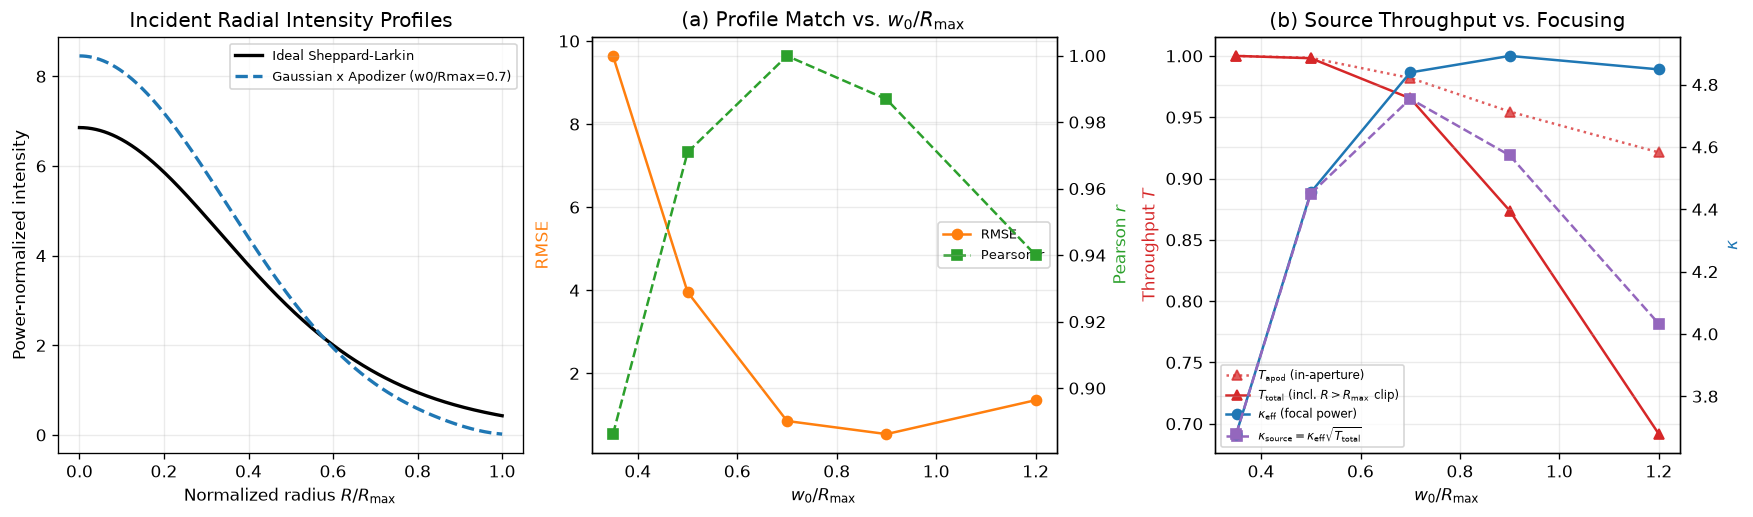

In [3]:
def compute_total_throughput(w0_over_rmax: float, apod_order: float, nr: int = 512) -> float:
    """Full source-to-mirror power throughput including clipping outside R > R_max."""
    if (
        not (math.isfinite(w0_over_rmax) and math.isfinite(apod_order))
        or w0_over_rmax <= 0.0
        or apod_order <= 0.0
    ):
        raise ValueError(
            f"w0_over_rmax and apod_order must be finite and positive, got ({w0_over_rmax}, {apod_order})"
        )
    r = np.linspace(0.0, 1.0, nr)
    gauss2 = np.exp(-2.0 * (r / w0_over_rmax) ** 2)
    apod2 = np.exp(-2.0 * (r ** (2.0 * apod_order)))
    p_mirror = float(np.trapezoid(gauss2 * apod2 * r, r))
    p_source_inf = (w0_over_rmax ** 2) / 4.0
    return p_mirror / p_source_inf


R, I_ideal, I_real = comparison.incident_intensity_profiles(
    f_number=cfg["f_number"],
    w0_over_rmax=cfg["w0_over_rmax"],
    apod_order=cfg["apod_order"],
)
rep = comparison.summarize_degradation(
    f_number=cfg["f_number"],
    w0_over_rmax=cfg["w0_over_rmax"],
    apod_order=cfg["apod_order"],
)

I_ideal_norm = I_ideal / np.trapezoid(I_ideal * R, R)
I_real_norm = I_real / np.trapezoid(I_real * R, R)
rmse = math.sqrt(rep["mse"])
rel_rmse = rmse / float(np.max(I_ideal_norm))
t_apod_cfg = rep["transmission"]
t_total_cfg = compute_total_throughput(cfg["w0_over_rmax"], cfg["apod_order"])

print(f"Profile comparison at f/{cfg['f_number']}, w0/R_max={cfg['w0_over_rmax']}, apod_order={cfg['apod_order']}:")
print(f"  MSE                            = {rep['mse']:.6f}")
print(f"  RMSE                           = {rmse:.6f}")
print(f"  Relative RMSE (RMSE/peak)      = {rel_rmse:.6f} ({100.0 * rel_rmse:.2f}%)")
print(f"  Pearson r                      = {rep['correlation']:.6f}")
print(f"  In-aperture T_apod (r in [0,1])= {t_apod_cfg:.6f} ({100.0 * t_apod_cfg:.2f}%)")
print(f"  Full-source T_total (incl clip)= {t_total_cfg:.6f} ({100.0 * t_total_cfg:.2f}%)")

w0_scan = [0.35, 0.5, 0.7, 0.9, 1.2]
scan_rmse = []
scan_corr = []
scan_trans_apod = []
scan_trans_total = []
scan_kappa_eff = []
scan_kappa_src = []

for w0_ratio in w0_scan:
    r_w0 = comparison.summarize_degradation(
        f_number=cfg["f_number"],
        w0_over_rmax=w0_ratio,
        apod_order=cfg["apod_order"],
    )
    sw_res = sweep.kappa_eff_vs_f_number(
        [cfg["f_number"]],
        lambda0_m=1.0e-6,
        power_w=1.0e15,
        energy_gev=1.0,
        far_field_builder=sweep.gaussian_far_field_builder(
            w0_over_rmax=w0_ratio, apod_order=cfg["apod_order"]
        ),
    )
    k_eff = sw_res[0]["chi_max_per_GeV"]
    t_apod_val = r_w0["transmission"]
    t_total_val = compute_total_throughput(w0_ratio, cfg["apod_order"])
    scan_rmse.append(math.sqrt(r_w0["mse"]))
    scan_corr.append(r_w0["correlation"])
    scan_trans_apod.append(t_apod_val)
    scan_trans_total.append(t_total_val)
    scan_kappa_eff.append(k_eff)
    scan_kappa_src.append(k_eff * math.sqrt(t_total_val))

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2), constrained_layout=True)

axes[0].plot(R, I_ideal_norm, "k-", linewidth=2.0, label="Ideal Sheppard-Larkin")
axes[0].plot(R, I_real_norm, "C0--", linewidth=2.0, label=f"Gaussian x Apodizer (w0/Rmax={cfg['w0_over_rmax']})")
axes[0].set_xlabel(r"Normalized radius $R / R_{\max}$")
axes[0].set_ylabel("Power-normalized intensity")
axes[0].set_title("Incident Radial Intensity Profiles")
axes[0].legend(fontsize=8)

ax0_r = axes[1].twinx()
l1 = axes[1].plot(w0_scan, scan_rmse, "C1o-", label="RMSE")
l2 = ax0_r.plot(w0_scan, scan_corr, "C2s--", label="Pearson $r$")
axes[1].set_xlabel(r"$w_0 / R_{\max}$")
axes[1].set_ylabel("RMSE", color="C1")
ax0_r.set_ylabel("Pearson $r$", color="C2")
axes[1].set_title(r"(a) Profile Match vs. $w_0 / R_{\max}$")
lines_1 = l1 + l2
axes[1].legend(lines_1, [l.get_label() for l in lines_1], loc="center right", fontsize=8)

ax2_r = axes[2].twinx()
l3a = axes[2].plot(w0_scan, scan_trans_apod, "C3^:", alpha=0.75, label=r"$T_{\mathrm{apod}}$ (in-aperture)")
l3b = axes[2].plot(w0_scan, scan_trans_total, "C3^-", label=r"$T_{\mathrm{total}}$ (incl. $R>R_{\max}$ clip)")
l4 = ax2_r.plot(w0_scan, scan_kappa_eff, "C0o-", label=r"$\kappa_{\mathrm{eff}}$ (focal power)")
l5 = ax2_r.plot(w0_scan, scan_kappa_src, "C4s--", label=r"$\kappa_{\mathrm{source}} = \kappa_{\mathrm{eff}}\sqrt{T_{\mathrm{total}}}$")
axes[2].set_xlabel(r"$w_0 / R_{\max}$")
axes[2].set_ylabel("Throughput $T$", color="C3")
ax2_r.set_ylabel(r"$\kappa$", color="C0")
axes[2].set_title("(b) Source Throughput vs. Focusing")
lines_2 = l3a + l3b + l4 + l5
axes[2].legend(lines_2, [l.get_label() for l in lines_2], loc="lower left", fontsize=7.0)

plt.show()

## 3. Section 2 — 3D Vectorial Focal Fields & `.npz` Boundary Handoff (`focus.py` $\rightarrow$ `.npz` $\rightarrow$ `fields.py`)

We generate 3D complex phasor field packs (`Ec`, `Bc`, `metadata`) for both `'gaussian'` and `'ideal'` modes, serialize them into separate subdirectories inside a `tempfile.TemporaryDirectory()` (keeping `data/` untouched), and reload them with `load_field_pack` to verify schema conformance, global phase alignment at $t_{\mathrm{ref}} = 0$, and focal-plane Poynting-flux conservation (`power_conservation_rel_err < 0.10`).

Bit-exact Ec/Bc roundtrip check passed for both 'gaussian' and 'ideal' packs.
Metric                           |         Gaussian |            Ideal
----------------------------------------------------------------------
a_max                            |         509.6701 |         517.6483
chi_max_per_GeV                  |       6.0500e+00 |       6.1447e+00
power_conservation_rel_err       |          1.5022% |          5.1048%
Ez(0, 0) [V/m]                   |       2.0455e+15 |       2.0775e+15
Bx(0, 0) [T]                     |      -6.8230e+06 |      -6.9299e+06


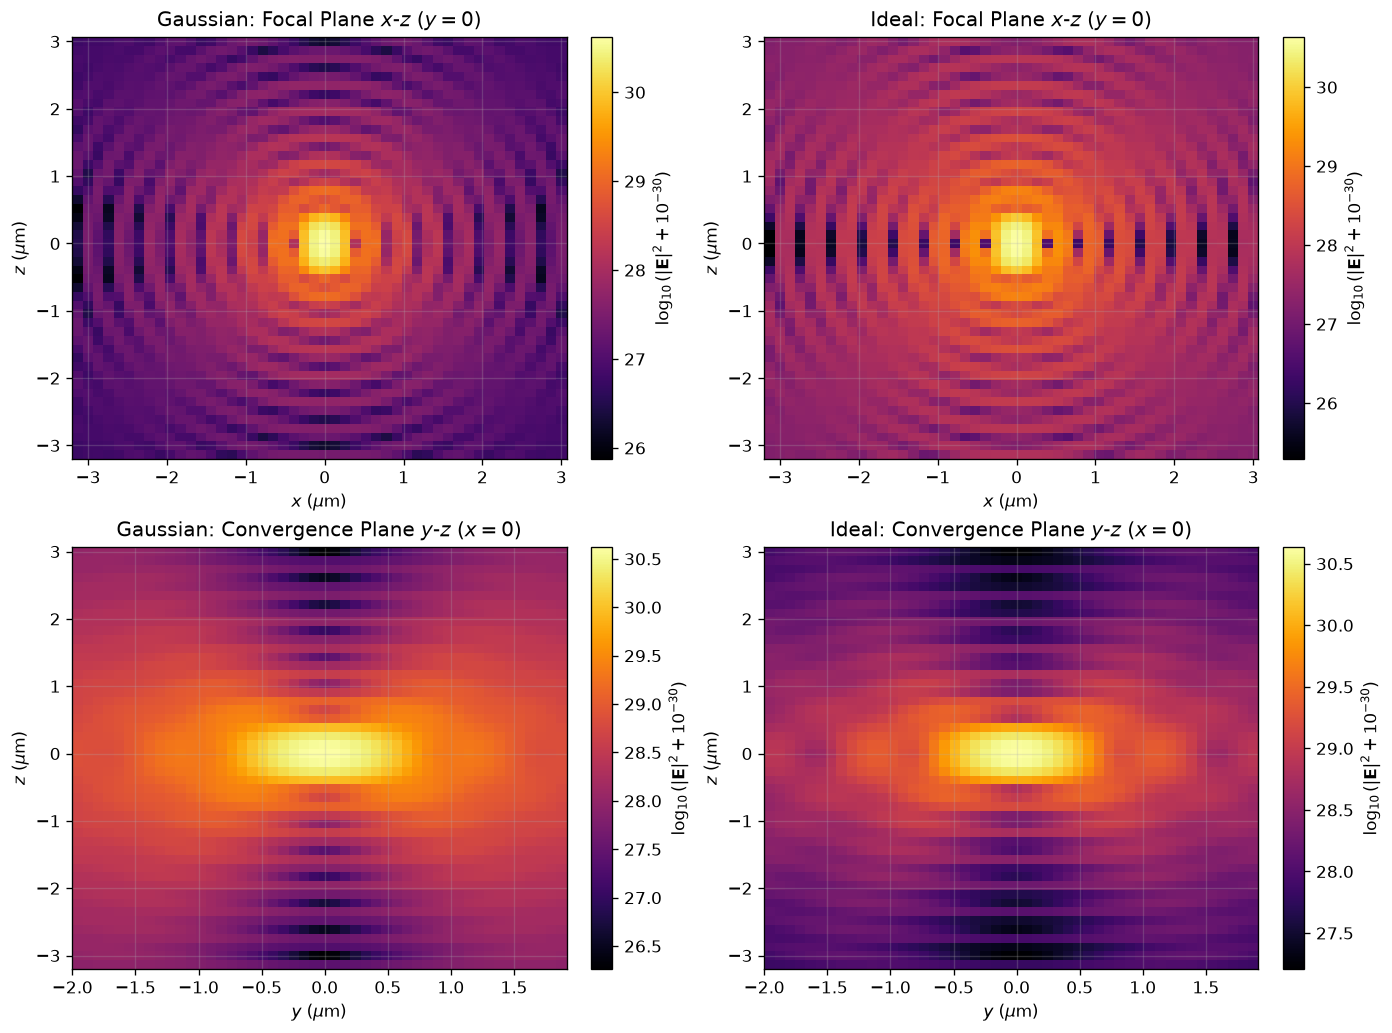

In [4]:
pack_gauss_raw = cli.generate_field_pack(build_optics_params(cfg, "gaussian"))
pack_ideal_raw = cli.generate_field_pack(build_optics_params(cfg, "ideal"))

with tempfile.TemporaryDirectory() as tmp_dir:
    tmp_root = Path(tmp_dir)
    path_gauss = cli.save_field_pack(pack_gauss_raw, out_dir=tmp_root / "gaussian")
    path_ideal = cli.save_field_pack(pack_ideal_raw, out_dir=tmp_root / "ideal")
    loaded_gauss = load_field_pack(path_gauss)
    loaded_ideal = load_field_pack(path_ideal)

assert np.allclose(loaded_gauss.Ec, pack_gauss_raw["Ec"], rtol=0, atol=0)
assert np.allclose(loaded_gauss.Bc, pack_gauss_raw["Bc"], rtol=0, atol=0)
assert np.allclose(loaded_ideal.Ec, pack_ideal_raw["Ec"], rtol=0, atol=0)
assert np.allclose(loaded_ideal.Bc, pack_ideal_raw["Bc"], rtol=0, atol=0)
assert loaded_gauss.checks.power_conservation_rel_err < 0.10
assert loaded_ideal.checks.power_conservation_rel_err < 0.10
print("Bit-exact Ec/Bc roundtrip check passed for both 'gaussian' and 'ideal' packs.")

r_origin = np.zeros(3, dtype=np.float64)
e_g0, b_g0 = evaluate_eb(loaded_gauss, r_origin, 0.0)
e_i0, b_i0 = evaluate_eb(loaded_ideal, r_origin, 0.0)

print(f"{'Metric':32s} | {'Gaussian':>16s} | {'Ideal':>16s}")
print("-" * 70)
print(f"{'a_max':32s} | {loaded_gauss.checks.a_max:16.4f} | {loaded_ideal.checks.a_max:16.4f}")
print(f"{'chi_max_per_GeV':32s} | {loaded_gauss.checks.chi_max_per_GeV:16.4e} | {loaded_ideal.checks.chi_max_per_GeV:16.4e}")
print(f"{'power_conservation_rel_err':32s} | {loaded_gauss.checks.power_conservation_rel_err:16.4%} | {loaded_ideal.checks.power_conservation_rel_err:16.4%}")
print(f"{'Ez(0, 0) [V/m]':32s} | {e_g0[2]:16.4e} | {e_i0[2]:16.4e}")
print(f"{'Bx(0, 0) [T]':32s} | {b_g0[0]:16.4e} | {b_i0[0]:16.4e}")

iy_mid = loaded_gauss.grid.Ny // 2
ix_mid = loaded_gauss.grid.Nx // 2
x_um = loaded_gauss.grid.x_axis * 1.0e6
y_um = loaded_gauss.grid.y_axis * 1.0e6
z_um = loaded_gauss.grid.z_axis * 1.0e6

ext_xz = [x_um[0], x_um[-1], z_um[0], z_um[-1]]
ext_yz = [y_um[0], y_um[-1], z_um[0], z_um[-1]]

fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.5), constrained_layout=True)
panels = [
    (axes[0, 0], loaded_gauss, "Gaussian", "xz"),
    (axes[0, 1], loaded_ideal, "Ideal", "xz"),
    (axes[1, 0], loaded_gauss, "Gaussian", "yz"),
    (axes[1, 1], loaded_ideal, "Ideal", "yz"),
]

for ax, pk, label, plane in panels:
    if plane == "xz":
        e_slice = pk.Ec[0, :, :, iy_mid, :]
        extent = ext_xz
        ax.set_xlabel(r"$x$ ($\mu$m)")
        ax.set_ylabel(r"$z$ ($\mu$m)")
        ax.set_title(f"{label}: Focal Plane $x$-$z$ ($y=0$)")
    else:
        e_slice = pk.Ec[0, :, :, :, ix_mid]
        extent = ext_yz
        ax.set_xlabel(r"$y$ ($\mu$m)")
        ax.set_ylabel(r"$z$ ($\mu$m)")
        ax.set_title(f"{label}: Convergence Plane $y$-$z$ ($x=0$)")

    e2_log = np.log10(np.sum(np.abs(e_slice) ** 2, axis=0) + 1.0e-30)
    im = ax.imshow(e2_log, origin="lower", extent=extent, aspect="auto", cmap="inferno")
    fig.colorbar(im, ax=ax, label=r"$\log_{10}(|\mathbf{E}|^2 + 10^{-30})$")

plt.show()

## 4. Section 3 — Aperture Sweep: $\kappa_{\mathrm{eff}}(f\text{-number})$ vs. Fig. 4 (`sweep.py`, `stats.fig4_reference_curve`)

We scan the parabolic-mirror $f$-number across $f \in [0.10, 4.0]$ (demonstrating `mirror_reflection_far_field` support below $f = 0.25$, where rays wrap past $\theta = 90^\circ$ into the $+\hat{\mathbf{y}}$ hemisphere) at $\lambda_0 = 1.0\ \mu\mathrm{m}$, $P = 1\ \mathrm{PW}$, $\varepsilon = 1\ \mathrm{GeV}$ so that $\chi_{\max}/\mathrm{GeV}$ directly equals $\kappa_{\mathrm{eff}}$.

Using full-source T_total = 0.9654 (vs. in-aperture T_apod = 0.9820) for gauss_source:
At f=0.25: analytic=4.911, ideal=4.915, gauss_focal=4.839, gauss_source=4.754
At f=2.00: analytic=1.119, ideal=1.120, gauss_focal=0.954, gauss_source=0.937  (proposal benchmark: ~1.1)
At f=0.10: analytic=5.243, ideal=5.248, gauss_focal=4.576, gauss_source=4.496


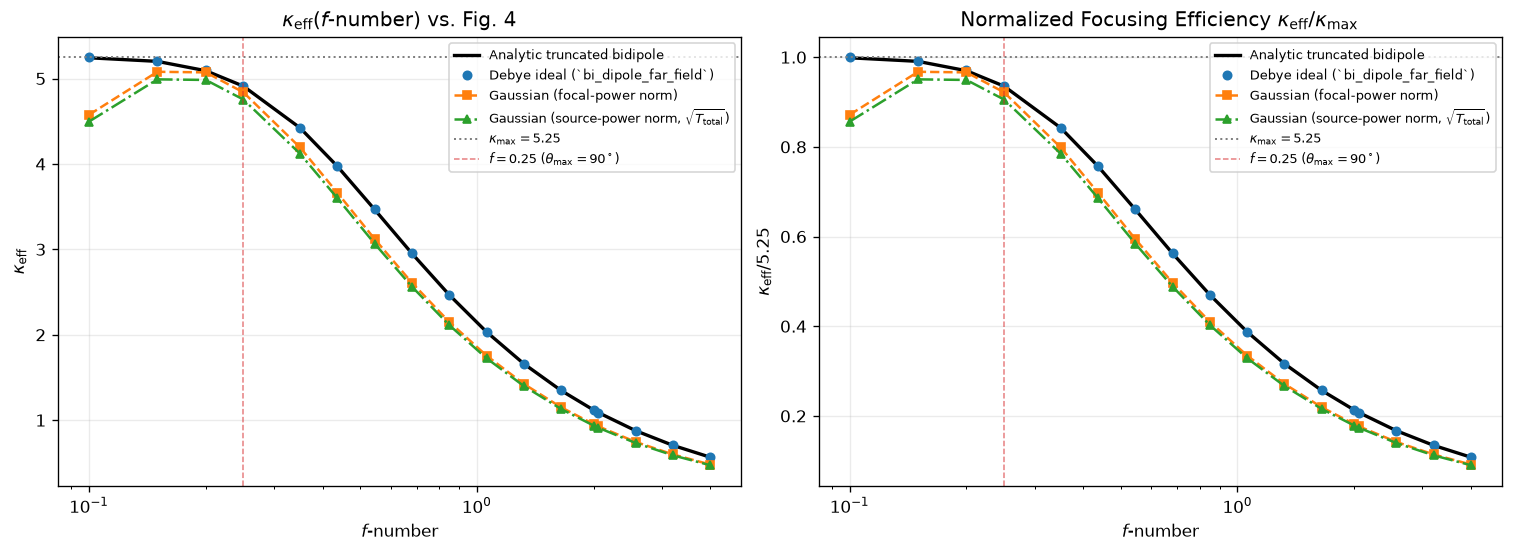

In [5]:
f_numbers = np.unique(
    np.sort(np.concatenate(([0.10, 0.15, 0.20, 0.25, 2.0], np.geomspace(0.35, 4.0, 12))))
)

ref_fig4 = fig4_reference_curve(
    f_numbers=f_numbers, power_w=1.0e15, energy_gev=1.0, lambda_m=1.0e-6
)
sw_ideal = sweep.kappa_eff_vs_f_number(
    f_numbers,
    lambda0_m=1.0e-6,
    power_w=1.0e15,
    energy_gev=1.0,
    far_field_builder=sweep.ideal_far_field_builder(),
)
sw_gauss = sweep.kappa_eff_vs_f_number(
    f_numbers,
    lambda0_m=1.0e-6,
    power_w=1.0e15,
    energy_gev=1.0,
    far_field_builder=sweep.gaussian_far_field_builder(
        w0_over_rmax=cfg["w0_over_rmax"], apod_order=cfg["apod_order"]
    ),
)

kappa_analytic = ref_fig4["kappa"]
kappa_ideal = np.array([d["chi_max_per_GeV"] for d in sw_ideal])
kappa_gauss_focal = np.array([d["chi_max_per_GeV"] for d in sw_gauss])
t_total_sweep = compute_total_throughput(cfg["w0_over_rmax"], cfg["apod_order"])
t_apod_sweep = comparison.apodizer_transmission(cfg["w0_over_rmax"], cfg["apod_order"])
kappa_gauss_source = kappa_gauss_focal * math.sqrt(t_total_sweep)

idx_f010 = int(np.argmin(np.abs(f_numbers - 0.10)))
idx_f025 = int(np.argmin(np.abs(f_numbers - 0.25)))
idx_f200 = int(np.argmin(np.abs(f_numbers - 2.0)))
assert np.isclose(f_numbers[idx_f025], 0.25) and np.isclose(f_numbers[idx_f200], 2.0)

print(f"Using full-source T_total = {t_total_sweep:.4f} (vs. in-aperture T_apod = {t_apod_sweep:.4f}) for gauss_source:")
print(f"At f=0.25: analytic={kappa_analytic[idx_f025]:.3f}, ideal={kappa_ideal[idx_f025]:.3f}, "
      f"gauss_focal={kappa_gauss_focal[idx_f025]:.3f}, gauss_source={kappa_gauss_source[idx_f025]:.3f}")
print(f"At f=2.00: analytic={kappa_analytic[idx_f200]:.3f}, ideal={kappa_ideal[idx_f200]:.3f}, "
      f"gauss_focal={kappa_gauss_focal[idx_f200]:.3f}, gauss_source={kappa_gauss_source[idx_f200]:.3f}  (proposal benchmark: ~1.1)")
print(f"At f=0.10: analytic={kappa_analytic[idx_f010]:.3f}, ideal={kappa_ideal[idx_f010]:.3f}, "
      f"gauss_focal={kappa_gauss_focal[idx_f010]:.3f}, gauss_source={kappa_gauss_source[idx_f010]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), constrained_layout=True)

for ax, norm in zip(axes, [1.0, 5.25]):
    ax.semilogx(f_numbers, kappa_analytic / norm, "k-", linewidth=2.0, label="Analytic truncated bidipole")
    ax.semilogx(f_numbers, kappa_ideal / norm, "C0o", markersize=5, label="Debye ideal (`bi_dipole_far_field`)")
    ax.semilogx(f_numbers, kappa_gauss_focal / norm, "C1s--", markersize=4.5, label="Gaussian (focal-power norm)")
    ax.semilogx(
        f_numbers,
        kappa_gauss_source / norm,
        "C2^-.",
        markersize=4.5,
        label=r"Gaussian (source-power norm, $\sqrt{T_{\mathrm{total}}}$)",
    )
    ax.axhline(5.25 / norm, color="gray", linestyle=":", linewidth=1.2, label=r"$\kappa_{\max} = 5.25$")
    ax.axvline(0.25, color="tab:red", linestyle="--", linewidth=0.9, alpha=0.6, label=r"$f = 0.25$ ($\theta_{\max}=90^\circ$)")
    ax.set_xlabel(r"$f$-number")
    ax.legend(fontsize=7.5)

axes[0].set_ylabel(r"$\kappa_{\mathrm{eff}}$")
axes[0].set_title(r"$\kappa_{\mathrm{eff}}(f\text{-number})$ vs. Fig. 4")
axes[1].set_ylabel(r"$\kappa_{\mathrm{eff}} / 5.25$")
axes[1].set_title(r"Normalized Focusing Efficiency $\kappa_{\mathrm{eff}} / \kappa_{\max}$")
plt.show()

## 5. Section 4 — Electron Trajectories, $\chi(b,t)$, $F(b)$, $\chi$ Distributions, and Fig. 2 Phase Space

We sample an electron ensemble distributed uniformly in transverse area ($p(b) = 2b / b_{\max}^2$) entering along $+\hat{\mathbf{y}}$ from $y_0$, propagate it with the relativistic Vay pusher (`signed_alpha=True`) through both the `'gaussian'` and `'ideal'` field packs, and inspect $\chi(t)$ traces, peak $\chi(b)$, high-$\chi$ residence fraction $F(b)$, the Fig. 2 $(u_\alpha, u_\chi)$ phase-space density, and the peak-$\chi$ / instantaneous-$\chi$ distributions.

Gaussian (N=2000): mean peak chi = 1.0730e+01, median = 8.1483e+00, p90 = 1.5674e+01, mean F(b) = 0.0035
Ideal    (N=2000): mean peak chi = 1.0453e+01, median = 7.8729e+00, p90 = 1.5239e+01, mean F(b) = 0.0027


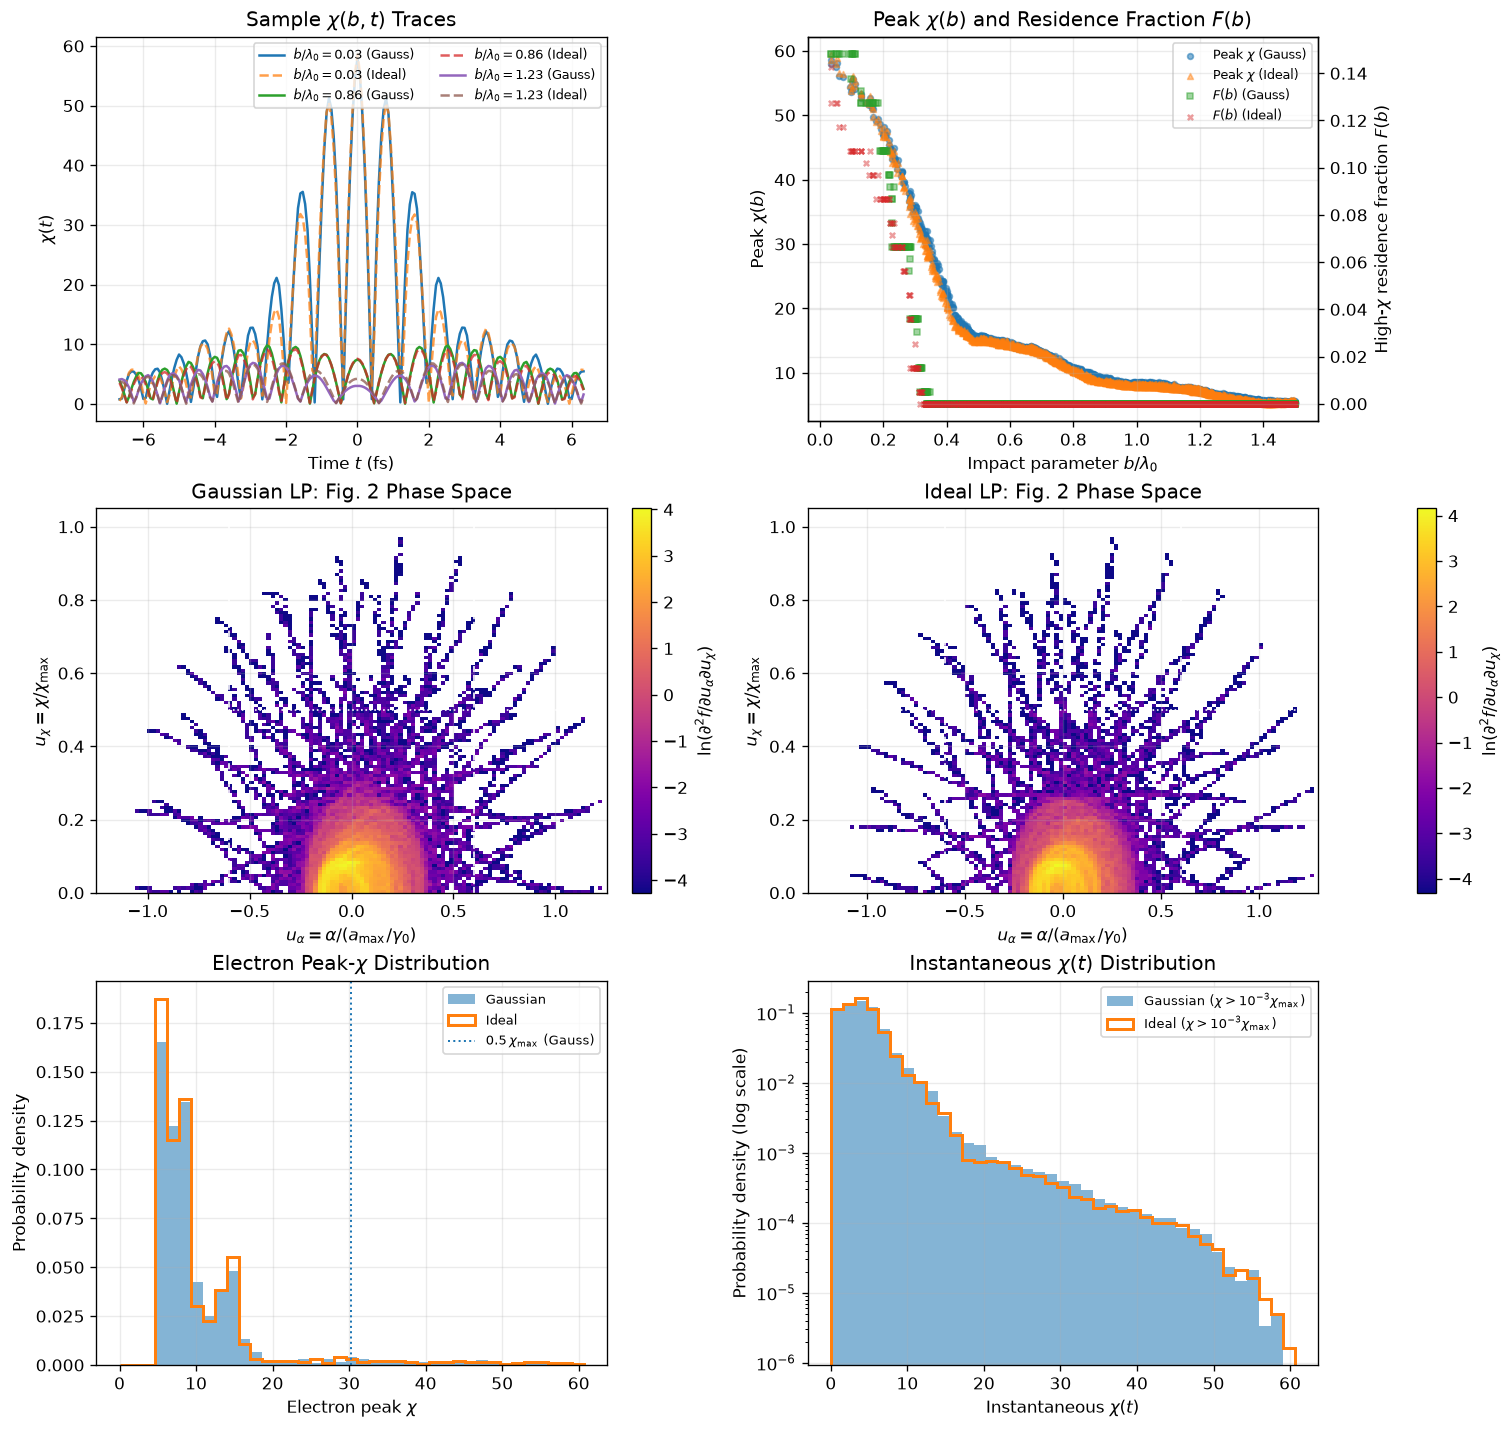

In [6]:
batch = sample_electron_batch(
    n_particles=cfg["n_particles"],
    energy_gev=cfg["energy_gev"],
    b_max_m=cfg["b_max_lambdas"] * loaded_gauss.lambda0_m,
    y0_m=loaded_gauss.grid.y0_m,
    sigma_dt_s=cfg["sigma_dt_s"],
    rng=np.random.default_rng(42),
)

traj_gauss = propagate_ensemble(loaded_gauss, batch, method="vay", signed_alpha=True)
traj_ideal = propagate_ensemble(loaded_ideal, batch, method="vay", signed_alpha=True)

dt_s = float(traj_gauss.t_s[1] - traj_gauss.t_s[0])
chi_max_gauss = loaded_gauss.checks.chi_max_per_GeV * cfg["energy_gev"]
chi_max_ideal = loaded_ideal.checks.chi_max_per_GeV * cfg["energy_gev"]

frac_gauss = compute_high_chi_time_fraction(traj_gauss.chi, dt_s, chi_max=chi_max_gauss)
frac_ideal = compute_high_chi_time_fraction(traj_ideal.chi, dt_s, chi_max=chi_max_ideal)

ps_gauss = compute_fig2_phase_space(
    traj_gauss.alpha,
    traj_gauss.chi,
    a_max=loaded_gauss.checks.a_max,
    gamma0=batch.gamma0,
    chi_max=chi_max_gauss,
    signed_alpha=True,
)
ps_ideal = compute_fig2_phase_space(
    traj_ideal.alpha,
    traj_ideal.chi,
    a_max=loaded_ideal.checks.a_max,
    gamma0=batch.gamma0,
    chi_max=chi_max_ideal,
    signed_alpha=True,
)

peak_chi_gauss = np.max(traj_gauss.chi, axis=1)
peak_chi_ideal = np.max(traj_ideal.chi, axis=1)

b_over_lam = batch.b_impact_m / loaded_gauss.lambda0_m
order_b = np.argsort(batch.b_impact_m)
sample_idx = [order_b[0], order_b[len(order_b) // 3], order_b[(2 * len(order_b)) // 3]]

print(
    f"Gaussian (N={len(peak_chi_gauss)}): mean peak chi = {np.mean(peak_chi_gauss):.4e}, "
    f"median = {np.median(peak_chi_gauss):.4e}, p90 = {np.percentile(peak_chi_gauss, 90):.4e}, "
    f"mean F(b) = {np.mean(frac_gauss):.4f}"
)
print(
    f"Ideal    (N={len(peak_chi_ideal)}): mean peak chi = {np.mean(peak_chi_ideal):.4e}, "
    f"median = {np.median(peak_chi_ideal):.4e}, p90 = {np.percentile(peak_chi_ideal, 90):.4e}, "
    f"mean F(b) = {np.mean(frac_ideal):.4f}"
)

fig, axes = plt.subplots(3, 2, figsize=(12.5, 11.8), constrained_layout=True)

t_fs = traj_gauss.t_s * 1.0e15
for idx in sample_idx:
    axes[0, 0].plot(
        t_fs, traj_gauss.chi[idx],
        label=rf"$b/\lambda_0 = {b_over_lam[idx]:.2f}$ (Gauss)"
    )
    axes[0, 0].plot(
        t_fs, traj_ideal.chi[idx], linestyle="--", alpha=0.75,
        label=rf"$b/\lambda_0 = {b_over_lam[idx]:.2f}$ (Ideal)"
    )
axes[0, 0].set_xlabel("Time $t$ (fs)")
axes[0, 0].set_ylabel(r"$\chi(t)$")
axes[0, 0].set_title(r"Sample $\chi(b, t)$ Traces")
axes[0, 0].legend(fontsize=7.5, ncol=2)

ax_r = axes[0, 1].twinx()
s1 = axes[0, 1].scatter(b_over_lam, peak_chi_gauss, s=12, alpha=0.55, c="C0", label=r"Peak $\chi$ (Gauss)")
s2 = axes[0, 1].scatter(b_over_lam, peak_chi_ideal, s=12, c="C1", marker="^", alpha=0.45, label=r"Peak $\chi$ (Ideal)")
s3 = ax_r.scatter(b_over_lam, frac_gauss, s=10, c="C2", marker="s", alpha=0.45, label=r"$F(b)$ (Gauss)")
s4 = ax_r.scatter(b_over_lam, frac_ideal, s=10, c="C3", marker="x", alpha=0.45, label=r"$F(b)$ (Ideal)")
axes[0, 1].set_xlabel(r"Impact parameter $b / \lambda_0$")
axes[0, 1].set_ylabel(r"Peak $\chi(b)$")
ax_r.set_ylabel(r"High-$\chi$ residence fraction $F(b)$")
axes[0, 1].set_title(r"Peak $\chi(b)$ and Residence Fraction $F(b)$")
handles = [s1, s2, s3, s4]
axes[0, 1].legend(handles, [h.get_label() for h in handles], fontsize=7.5, loc="upper right")

for ax, ps, title in [
    (axes[1, 0], ps_gauss, "Gaussian LP: Fig. 2 Phase Space"),
    (axes[1, 1], ps_ideal, "Ideal LP: Fig. 2 Phase Space"),
]:
    im = ax.pcolormesh(ps["u_alpha_edges"], ps["u_chi_edges"], ps["log_density"], cmap="plasma")
    ax.axvline(-0.6, color="w", linestyle="--", linewidth=1.0)
    ax.axvline(0.6, color="w", linestyle="--", linewidth=1.0)
    ax.axhline(0.5, color="w", linestyle=":", linewidth=1.0)
    ax.set_xlabel(r"$u_\alpha = \alpha / (a_{\max} / \gamma_0)$")
    ax.set_ylabel(r"$u_\chi = \chi / \chi_{\max}$")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label=r"$\ln(\partial^2 f / \partial u_\alpha \partial u_\chi)$")

chi_bins = np.linspace(0.0, max(float(np.max(peak_chi_gauss)), float(np.max(peak_chi_ideal))) * 1.02, 40)
axes[2, 0].hist(peak_chi_gauss, bins=chi_bins, density=True, alpha=0.55, color="C0", label="Gaussian")
axes[2, 0].hist(peak_chi_ideal, bins=chi_bins, density=True, histtype="step", linewidth=1.8, color="C1", label="Ideal")
axes[2, 0].axvline(0.5 * chi_max_gauss, color="C0", linestyle=":", linewidth=1.2, label=r"$0.5\,\chi_{\max}$ (Gauss)")
axes[2, 0].set_xlabel(r"Electron peak $\chi$")
axes[2, 0].set_ylabel("Probability density")
axes[2, 0].set_title(r"Electron Peak-$\chi$ Distribution")
axes[2, 0].legend(fontsize=8)

chi_thresh_g = 1.0e-3 * chi_max_gauss
chi_thresh_i = 1.0e-3 * chi_max_ideal
inst_g = traj_gauss.chi[traj_gauss.chi > chi_thresh_g]
inst_i = traj_ideal.chi[traj_ideal.chi > chi_thresh_i]
if inst_g.size > 0 and inst_i.size > 0:
    inst_bins = np.linspace(0.0, max(float(np.max(inst_g)), float(np.max(inst_i))) * 1.02, 40)
    axes[2, 1].hist(inst_g, bins=inst_bins, density=True, alpha=0.55, color="C0", label=r"Gaussian ($\chi > 10^{-3}\chi_{\max}$)")
    axes[2, 1].hist(inst_i, bins=inst_bins, density=True, histtype="step", linewidth=1.8, color="C1", label=r"Ideal ($\chi > 10^{-3}\chi_{\max}$)")
    axes[2, 1].set_yscale("log")
axes[2, 1].set_xlabel(r"Instantaneous $\chi(t)$")
axes[2, 1].set_ylabel("Probability density (log scale)")
axes[2, 1].set_title(r"Instantaneous $\chi(t)$ Distribution")
axes[2, 1].legend(fontsize=8)

plt.show()

## 6. Section 5 — Strong-Field QED Emission, Selection Cuts ($\sigma$, $\eta$), and $3\sigma$ Shot Count

We build the LCFA emission lookup table (`build_lcfa_table()`), simulate weighted photon emission (`simulate_qed_ensemble(..., mode='weighted')`), apply the Sec. V selection cuts ($\delta_{\mathrm{init}} > 0.5$, $\alpha > 0.6\,a_{\max}/\gamma_0$ for LP signal+background, and additionally $\chi > 0.5\,\chi_{\max}$, $\gamma_{\mathrm{prior}} \ge 0.99\gamma_0$ for the clean SFQED signal), and compute the $3\sigma$ photon-detection shot requirement (passing `tau_l_s` explicitly from the loaded field pack) alongside the electron energy-loss benchmark. At the end, we explicitly verify Olofsson & Gonoskov's Sec. V benchmark point ($100\ \mathrm{TW}$, $10\ \mathrm{GeV}$, 5-cycle, $f/0.25$, $\sim 200$ shots).

QED Metric                       |         Gaussian |            Ideal
----------------------------------------------------------------------
tau_fwhm_s [s]                   |       1.3343e-14 |       1.3343e-14
sigma [cm^2]                     |       3.6715e-13 |       5.2357e-13
eta (signal / total)             |           0.1939 |           0.2247
3-sigma photon shots             |       1.6292e+03 |       8.5081e+02
Electron loss shots              |       1.5655e+11 |       2.2447e+11


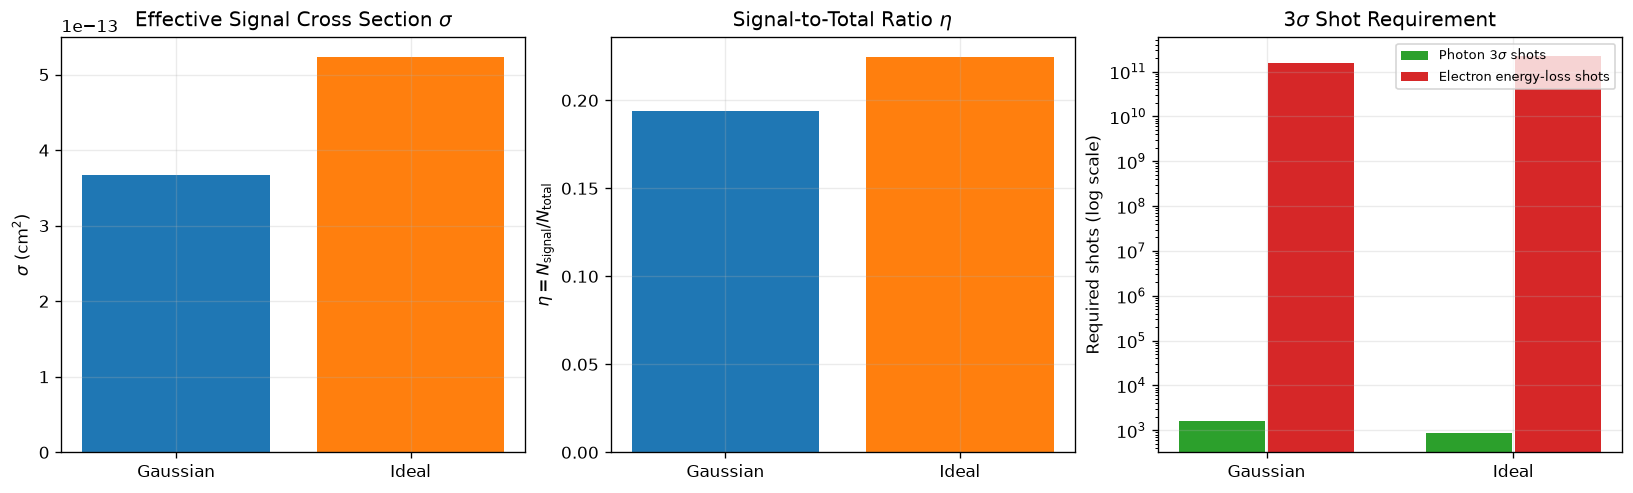


Paper Sec. V Benchmark Verification (100 TW, 10 GeV, 5-cycle, f/0.25, ideal mode, N=2000):
  chi_max       = 19.4313
  sigma         = 4.5995e-12 cm^2
  eta           = 0.1263
  3-sigma shots = 306.88 (Olofsson & Gonoskov Sec. V estimate: ~200 shots)


In [7]:
table = build_lcfa_table()

qed_gauss = simulate_qed_ensemble(loaded_gauss, batch, mode="weighted", table=table)
qed_ideal = simulate_qed_ensemble(loaded_ideal, batch, mode="weighted", table=table)

metrics_gauss = compute_sigma_and_eta(
    qed_gauss.photons,
    pol=loaded_gauss.pol,
    a_max=loaded_gauss.checks.a_max,
    chi_max=chi_max_gauss,
    b_max_m=batch.b_max_m,
    n_electrons=len(batch.b_impact_m),
)
metrics_ideal = compute_sigma_and_eta(
    qed_ideal.photons,
    pol=loaded_ideal.pol,
    a_max=loaded_ideal.checks.a_max,
    chi_max=chi_max_ideal,
    b_max_m=batch.b_max_m,
    n_electrons=len(batch.b_impact_m),
)


def safe_shot_estimate(metrics: dict[str, float], tau_l_s: float):
    if metrics["sigma_cm2"] > 0.0 and metrics["eta"] > 0.0:
        return estimate_shots_for_confidence(
            metrics["sigma_cm2"],
            metrics["eta"],
            tau_l_s=tau_l_s,
        )
    return None


shots_gauss = safe_shot_estimate(metrics_gauss, tau_l_s=loaded_gauss.pulse.tau_fwhm_s)
shots_ideal = safe_shot_estimate(metrics_ideal, tau_l_s=loaded_ideal.pulse.tau_fwhm_s)
eloss_gauss = estimate_electron_loss_shots(chi=chi_max_gauss, a_max=loaded_gauss.checks.a_max)
eloss_ideal = estimate_electron_loss_shots(chi=chi_max_ideal, a_max=loaded_ideal.checks.a_max)

print(f"{'QED Metric':32s} | {'Gaussian':>16s} | {'Ideal':>16s}")
print("-" * 70)
print(f"{'tau_fwhm_s [s]':32s} | {loaded_gauss.pulse.tau_fwhm_s:16.4e} | {loaded_ideal.pulse.tau_fwhm_s:16.4e}")
print(f"{'sigma [cm^2]':32s} | {metrics_gauss['sigma_cm2']:16.4e} | {metrics_ideal['sigma_cm2']:16.4e}")
print(f"{'eta (signal / total)':32s} | {metrics_gauss['eta']:16.4f} | {metrics_ideal['eta']:16.4f}")
g_sh_str = f"{shots_gauss.n_shots_required:.4e}" if shots_gauss is not None else "N/A (sigma=0)"
i_sh_str = f"{shots_ideal.n_shots_required:.4e}" if shots_ideal is not None else "N/A (sigma=0)"
print(f"{'3-sigma photon shots':32s} | {g_sh_str:>16s} | {i_sh_str:>16s}")
print(f"{'Electron loss shots':32s} | {eloss_gauss['shots_required']:16.4e} | {eloss_ideal['shots_required']:16.4e}")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0), constrained_layout=True)
labels = ["Gaussian", "Ideal"]
x_pos = np.arange(2)

axes[0].bar(x_pos, [metrics_gauss["sigma_cm2"], metrics_ideal["sigma_cm2"]], color=["C0", "C1"])
axes[0].set_xticks(x_pos, labels)
axes[0].set_ylabel(r"$\sigma$ (cm$^2$)")
axes[0].set_title(r"Effective Signal Cross Section $\sigma$")

axes[1].bar(x_pos, [metrics_gauss["eta"], metrics_ideal["eta"]], color=["C0", "C1"])
axes[1].set_xticks(x_pos, labels)
axes[1].set_ylabel(r"$\eta = N_{\mathrm{signal}} / N_{\mathrm{total}}$")
axes[1].set_title(r"Signal-to-Total Ratio $\eta$")

eloss_vals = [eloss_gauss["shots_required"], eloss_ideal["shots_required"]]
if shots_gauss is not None and shots_ideal is not None:
    photon_vals = [shots_gauss.n_shots_required, shots_ideal.n_shots_required]
    all_vals = [v for v in photon_vals + eloss_vals if v > 0.0]
    axes[2].bar(
        x_pos - 0.18,
        photon_vals,
        width=0.35,
        label=r"Photon $3\sigma$ shots",
        color="C2",
        log=True,
    )
    axes[2].bar(
        x_pos + 0.18,
        eloss_vals,
        width=0.35,
        label="Electron energy-loss shots",
        color="C3",
        log=True,
    )
    if all_vals and min(all_vals) <= 1.0:
        axes[2].set_ylim(bottom=min(all_vals) * 0.3, top=max(all_vals) * 3.0)
        axes[2].axhline(1.0, color="gray", linestyle=":", linewidth=1.0, label="1 shot")
    axes[2].set_xticks(x_pos, labels)
    axes[2].set_ylabel("Required shots (log scale)")
    axes[2].set_title(r"$3\sigma$ Shot Requirement")
    axes[2].legend(fontsize=8)
else:
    pos_eloss = [v for v in eloss_vals if v > 0.0]
    if pos_eloss:
        axes[2].bar(
            x_pos,
            eloss_vals,
            width=0.4,
            color="C3",
            label="Electron energy-loss shots",
            log=True,
        )
        if min(pos_eloss) <= 1.0:
            axes[2].set_ylim(bottom=min(pos_eloss) * 0.3, top=max(10.0, max(pos_eloss) * 3.0))
            axes[2].axhline(1.0, color="gray", linestyle=":", linewidth=1.0, label="1 shot")
    axes[2].set_xticks(x_pos, labels)
    axes[2].set_ylabel("Required shots (log scale)")
    axes[2].set_title(r"$3\sigma$ Shot Requirement")
    axes[2].text(
        0.5, 0.5,
        "Photon 3-sigma shots N/A\n(sigma = 0 or eta = 0 in low-chi regime)",
        transform=axes[2].transAxes,
        ha="center", va="center",
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.8),
        fontsize=8,
    )
    axes[2].legend(fontsize=8, loc="upper right")

plt.show()

# Dedicated benchmark verification: Olofsson & Gonoskov Sec. V (100 TW, 10 GeV, 5-cycle, f/0.25)
bench_lambda0_m = 0.8e-6
bench_params = {
    "lambda0_m": bench_lambda0_m,
    "f_number": 0.25,
    "power_w": 100.0e12,
    "pol": "z-linear",
    "tau_fwhm_s": None,
    "n_cycles": 5.0,
    "energy_gev": 10.0,
    "mode": "ideal",
    "w0_over_rmax": cfg["w0_over_rmax"],
    "apod_order": cfg["apod_order"],
    "nx": cfg["nx"],
    "ny": cfg["ny"],
    "nz": cfg["nz"],
    "span_xy_m": cfg["span_xy_lambdas"] * bench_lambda0_m,
    "span_y_m": cfg["span_y_lambdas"] * bench_lambda0_m,
    "ntheta": cfg["ntheta"],
    "nphi": cfg["nphi"],
    "focal_length_m": None,
}
pack_bench_raw = cli.generate_field_pack(bench_params)
with tempfile.TemporaryDirectory() as tmp_bench:
    path_bench = cli.save_field_pack(pack_bench_raw, out_dir=Path(tmp_bench))
    loaded_bench = load_field_pack(path_bench)

batch_bench = sample_electron_batch(
    n_particles=2000,
    energy_gev=10.0,
    b_max_m=1.5 * loaded_bench.lambda0_m,
    y0_m=loaded_bench.grid.y0_m,
    sigma_dt_s=0.0,
    rng=np.random.default_rng(42),
)
qed_bench = simulate_qed_ensemble(loaded_bench, batch_bench, mode="weighted", table=table)
chi_max_bench = loaded_bench.checks.chi_max_per_GeV * 10.0
metrics_bench = compute_sigma_and_eta(
    qed_bench.photons,
    pol=loaded_bench.pol,
    a_max=loaded_bench.checks.a_max,
    chi_max=chi_max_bench,
    b_max_m=batch_bench.b_max_m,
    n_electrons=len(batch_bench.b_impact_m),
)
shots_bench = safe_shot_estimate(metrics_bench, tau_l_s=loaded_bench.pulse.tau_fwhm_s)
print("\nPaper Sec. V Benchmark Verification (100 TW, 10 GeV, 5-cycle, f/0.25, ideal mode, N=2000):")
print(f"  chi_max       = {chi_max_bench:.4f}")
print(f"  sigma         = {metrics_bench['sigma_cm2']:.4e} cm^2")
print(f"  eta           = {metrics_bench['eta']:.4f}")
if shots_bench is not None:
    print(f"  3-sigma shots = {shots_bench.n_shots_required:.2f} (Olofsson & Gonoskov Sec. V estimate: ~200 shots)")
else:
    print("  3-sigma shots = N/A (sigma=0 or eta=0)")

## 7. Section 6 — Multi-Parameter Variation & Campus Ti:Sapphire Scaling

Finally, we bridge the PW collider regime and a campus-scale Ti:Sapphire beamline across three axes:
- **Panel A**: Wavelength tuning across $390\text{–}1040\ \mathrm{nm}$ comparing $\chi_{\max}/\mathrm{GeV}$ at $P = 13\ \mathrm{kW}$ (UNAL Ti:Sapphire) vs. $P = 1\ \mathrm{PW}$ (FSQED) using $\kappa_{\mathrm{eff}}$ extracted from `loaded_gauss`.
- **Panel B**: $\chi_{\max} / 2$ Landscape & Contours (Eq. 1) over $(\varepsilon, P)$ showing $\log_{10}(\chi_{\max}/2)$ and the $\chi_{\max}/2 \in \{1, 10, 100, 1000\}$ contours (`fig5_reference_contours`).
- **Panel C**: Timing jitter sweep over $\sigma_{\Delta t} / \tau_{\mathrm{FWHM}} \in \{0, 0.25, 0.5, 1.0\}$ on `loaded_gauss` (using `jitter_mode='per_particle'` across 400 electrons to measure ensemble-averaged degradation).

Extracted gaussian pack kappa_eff = 4.8400
UNAL Ti:Sapphire (13 kW, 800 nm): chi_max/GeV = 2.1814e-05 / GeV
Timing jitter sweep on Gaussian pack (N=400):
  sigma_dt/tau_FWHM = 0.00 -> mean peak chi = 1.0518e+01, mean F = 0.0028
  sigma_dt/tau_FWHM = 0.25 -> mean peak chi = 1.0435e+01, mean F = 0.0018
  sigma_dt/tau_FWHM = 0.50 -> mean peak chi = 9.2998e+00, mean F = 0.0009
  sigma_dt/tau_FWHM = 1.00 -> mean peak chi = 6.8420e+00, mean F = 0.0002


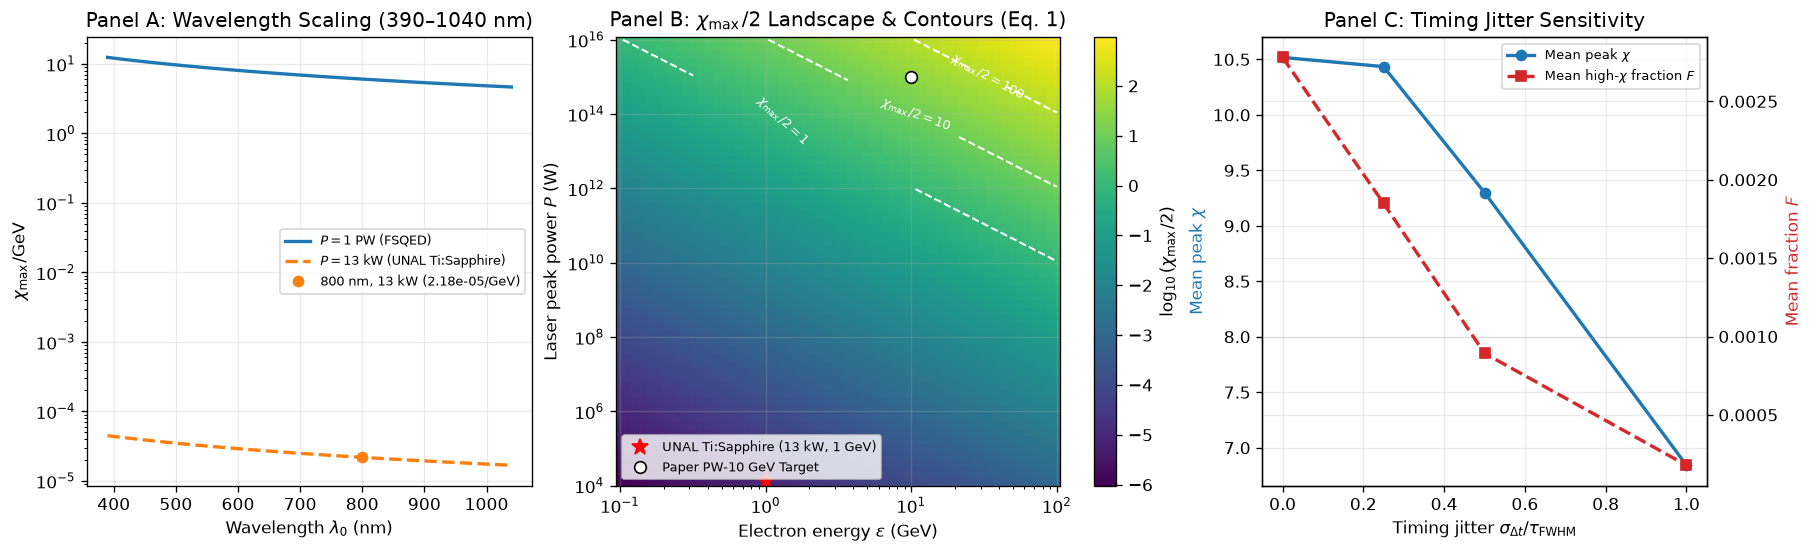

In [8]:
kappa_gauss_pack = loaded_gauss.checks.chi_max_per_GeV / (
    math.sqrt(loaded_gauss.power_W / 1.0e15) * (1.0e-6 / loaded_gauss.lambda0_m)
)

# Panel A: Wavelength sweep 390 - 1040 nm
lambdas_m = np.linspace(390.0e-9, 1040.0e-9, 30)
chi_13kw = np.array([
    theoretical_chi_max(1.0, 13.0e3, float(lam), kappa=kappa_gauss_pack)
    for lam in lambdas_m
])
chi_1pw = np.array([
    theoretical_chi_max(1.0, 1.0e15, float(lam), kappa=kappa_gauss_pack)
    for lam in lambdas_m
])
chi_800nm_13kw = theoretical_chi_max(1.0, 13.0e3, 800.0e-9, kappa=kappa_gauss_pack)
print(f"Extracted gaussian pack kappa_eff = {kappa_gauss_pack:.4f}")
print(f"UNAL Ti:Sapphire (13 kW, 800 nm): chi_max/GeV = {chi_800nm_13kw:.4e} / GeV")

# Panel B: chi_max / 2 landscape & contours (Eq. 1)
eps_grid = np.geomspace(0.1, 100.0, 60)
p_grid = np.geomspace(1.0e4, 1.0e16, 60)
fig5 = fig5_reference_contours(
    energy_gev_grid=eps_grid,
    power_w_grid=p_grid,
    lambda_m=cfg["lambda0_m"],
    kappa=kappa_gauss_pack,
)

# Panel C: Timing jitter sweep on loaded_gauss (n_particles = 400)
jitter_fracs = [0.0, 0.25, 0.5, 1.0]
mean_peak_chi_jitter = []
mean_f_jitter = []
tau_fwhm_g = loaded_gauss.pulse.tau_fwhm_s

for frac_j in jitter_fracs:
    batch_j = sample_electron_batch(
        n_particles=400,
        energy_gev=cfg["energy_gev"],
        b_max_m=cfg["b_max_lambdas"] * loaded_gauss.lambda0_m,
        y0_m=loaded_gauss.grid.y0_m,
        sigma_dt_s=frac_j * tau_fwhm_g,
        jitter_mode="per_particle",
        rng=np.random.default_rng(42),
    )
    traj_j = propagate_ensemble(loaded_gauss, batch_j, method="vay", signed_alpha=True)
    dt_j = float(traj_j.t_s[1] - traj_j.t_s[0])
    f_j = compute_high_chi_time_fraction(traj_j.chi, dt_j, chi_max=chi_max_gauss)
    mean_peak_chi_jitter.append(float(np.mean(np.max(traj_j.chi, axis=1))))
    mean_f_jitter.append(float(np.mean(f_j)))

print("Timing jitter sweep on Gaussian pack (N=400):")
for fj, pkc, mfj in zip(jitter_fracs, mean_peak_chi_jitter, mean_f_jitter):
    print(f"  sigma_dt/tau_FWHM = {fj:4.2f} -> mean peak chi = {pkc:.4e}, mean F = {mfj:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.5), constrained_layout=True)

# Plot Panel A
axes[0].semilogy(lambdas_m * 1.0e9, chi_1pw, "C0-", linewidth=2.0, label=r"$P = 1\ \mathrm{PW}$ (FSQED)")
axes[0].semilogy(lambdas_m * 1.0e9, chi_13kw, "C1--", linewidth=2.0, label=r"$P = 13\ \mathrm{kW}$ (UNAL Ti:Sapphire)")
axes[0].plot(800.0, chi_800nm_13kw, "C1o", markersize=6, label=rf"800 nm, 13 kW ({chi_800nm_13kw:.2e}/GeV)")
axes[0].set_xlabel(r"Wavelength $\lambda_0$ (nm)")
axes[0].set_ylabel(r"$\chi_{\max} / \mathrm{GeV}$")
axes[0].set_title("Panel A: Wavelength Scaling (390–1040 nm)")
axes[0].legend(fontsize=7.5)

# Plot Panel B
log_chi_half = np.log10(fig5["chi_half_grid"])
im_b = axes[1].pcolormesh(eps_grid, p_grid, log_chi_half, cmap="viridis", shading="auto")
cs = axes[1].contour(
    eps_grid, p_grid, fig5["chi_half_grid"],
    levels=fig5["levels"], colors="white", linewidths=1.2, linestyles="--",
)
axes[1].clabel(cs, fmt=lambda v: rf"$\chi_{{\max}}/2={int(v)}$", fontsize=7.5)
axes[1].plot(1.0, 13.0e3, "r*", markersize=10, label="UNAL Ti:Sapphire (13 kW, 1 GeV)")
axes[1].plot(10.0, 1.0e15, "wo", markersize=7, markeredgecolor="k", label="Paper PW-10 GeV Target")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel(r"Electron energy $\varepsilon$ (GeV)")
axes[1].set_ylabel(r"Laser peak power $P$ (W)")
axes[1].set_title(r"Panel B: $\chi_{\max} / 2$ Landscape & Contours (Eq. 1)")
axes[1].legend(fontsize=7.5, loc="lower left")
fig.colorbar(im_b, ax=axes[1], label=r"$\log_{10}(\chi_{\max}/2)$")

# Plot Panel C
ax_c_r = axes[2].twinx()
lc1 = axes[2].plot(jitter_fracs, mean_peak_chi_jitter, "C0o-", linewidth=2.0, label=r"Mean peak $\chi$")
lc2 = ax_c_r.plot(jitter_fracs, mean_f_jitter, "C3s--", linewidth=2.0, label=r"Mean high-$\chi$ fraction $F$")
axes[2].set_xlabel(r"Timing jitter $\sigma_{\Delta t} / \tau_{\mathrm{FWHM}}$")
axes[2].set_ylabel(r"Mean peak $\chi$", color="C0")
ax_c_r.set_ylabel(r"Mean fraction $F$", color="C3")
axes[2].set_title("Panel C: Timing Jitter Sensitivity")
lines_c = lc1 + lc2
axes[2].legend(lines_c, [l.get_label() for l in lines_c], loc="upper right", fontsize=8)

plt.show()